# SRMIST Tiruchirappalli — Deep Learning CBL Challenge
## Problem Statement PS-41: Kannada Handwritten Digit Recognition & Domain-Shift Analysis

> **STUDENT METADATA & ACADEMIC DECLARATION:**
> - **Student Name:** Aswin S
> - **Register Number:** `RA2311026050067`
> - **Degree & Branch:** B.Tech CSE (Artificial Intelligence & Machine Learning)
> - **Year & Semester:** IV Year / VII Semester
> - **Course:** Deep Learning — Challenge-Based Learning (CBL) Image Classification Challenge
> - **Problem Statement:** PS-41: Kannada Handwritten Digit Recognition (Domain: Indian Scripts, Signs & Currency)
> - **GitHub Repository:** `https://github.com/Aswin480/Kannada-MNIST-PS41`
> - **Official Dataset:** Kaggle Kannada-MNIST Benchmark (`https://www.kaggle.com/c/Kannada-MNIST`, Prabhu 2019)
> - **Execution Environment:** Python 3.11, PyTorch 2.1.0 (CPU Multithreading)


---
## 1. Problem Statement and Primary Objectives

Kannada is a major Dravidian language spoken by over 45 million people primarily in Karnataka, India. While Latin digit recognition (MNIST) is widely studied, Indic scripts feature unique topological nuances, delicate curvature, and orientation-dependent semantics.

The objectives of this project are:
1. **Primary Classification Objective:** Build a compact, robust Convolutional Neural Network (CNN) from scratch to accurately classify 28×28 grayscale Kannada numerals (classes 0 to 9, from 'Sonne' to 'Ombattu').
2. **Core Research Challenge (Domain Shift):** Quantify, analyze, and explain the performance shift when evaluating the trained model on `Dig-MNIST.csv`—an independent evaluation dataset gathered from completely different volunteer cohorts under varying pressure, pen types, and writing styles.
3. **Controlled Innovation Improvement:** Implement an evidence-based improvement (label-preserving data augmentation with cosine annealing schedule) to mitigate the domain-shift gap without training on the target domain.
4. **Final Unlabeled Predictions:** Generate verified predictions for `test.csv` conforming strictly to `sample_submission.csv`.


---
## 2. Environment Setup, Imports, and Reproducibility

We fix all random seeds across Python, NumPy, and PyTorch to ensure exact reproducibility across multiple runs.


In [1]:
import os
import sys
import time
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_recall_fscore_support

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Global Reproducibility Configuration
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"System Information:")
print(f" - Python Version:  {sys.version.split()[0]}")
print(f" - PyTorch Version: {torch.__version__}")
print(f" - Active Device:   {device}")
print(f" - Random Seed:     {SEED}")


System Information:
 - Python Version:  3.11.7
 - PyTorch Version: 2.1.0+cpu
 - Active Device:   cpu
 - Random Seed:     42


---
## 3. Dataset Inspection, Schema Verification, and Statistical Summary

We inspect all four project CSV files to verify:
- Label, ID, and Pixel feature columns
- Missing values and duplicate records
- Sample counts and class distribution balance
- Pixel intensity statistics across standard training and Dig-MNIST sets


In [2]:
# Load inspection summary generated during EDA
with open('outputs/reports/data_inspection_summary.json', 'r') as f:
    inspection = json.load(f)

for name, info in inspection.items():
    print(f"=== Dataset: {name} ===")
    print(f"  Shape:           {info['shape']}")
    print(f"  Missing Values:  {info['missing_values']}")
    print(f"  Duplicate Rows:  {info['duplicate_rows']}")
    if 'class_counts' in info:
        print(f"  Class Balance:   {info['class_counts']}")
    if 'pixel_mean' in info:
        print(f"  Pixel Range:     [{info['pixel_min']}, {info['pixel_max']}]")
        print(f"  Pixel Mean:      {info['pixel_mean']:.2f} (Std: {info['pixel_std']:.2f})")
    print()


=== Dataset: train ===
  Shape:           [60000, 785]
  Missing Values:  0
  Duplicate Rows:  0
  Class Balance:   {'0': 6000, '1': 6000, '2': 6000, '3': 6000, '4': 6000, '5': 6000, '6': 6000, '7': 6000, '8': 6000, '9': 6000}
  Pixel Range:     [0, 255]
  Pixel Mean:      20.99 (Std: 61.65)

=== Dataset: test ===
  Shape:           [5000, 785]
  Missing Values:  0
  Duplicate Rows:  0
  Pixel Range:     [0, 255]
  Pixel Mean:      18.52 (Std: 57.49)

=== Dataset: Dig-MNIST ===
  Shape:           [10240, 785]
  Missing Values:  0
  Duplicate Rows:  0
  Class Balance:   {'0': 1024, '1': 1024, '2': 1024, '3': 1024, '4': 1024, '5': 1024, '6': 1024, '7': 1024, '8': 1024, '9': 1024}
  Pixel Range:     [0, 255]
  Pixel Mean:      28.73 (Std: 72.93)

=== Dataset: sample_submission ===
  Shape:           [5000, 2]
  Missing Values:  0
  Duplicate Rows:  0
  Class Balance:   {'5': 5000}



---
## 4. Genuine Kannada Digit Visualizations

We display genuine handwritten samples from each of the 10 classes, along with their phonetic names and traditional Kannada numeral symbols:
- **0: Sonne (೦)**
- **1: Ondu (೧)**
- **2: Eradu (೨)**
- **3: Mooru (೩)**
- **4: Naalku (೪)**
- **5: Aidu (೫)**
- **6: Aaru (೬)**
- **7: Eylu (೭)**
- **8: Entu (೮)**
- **9: Ombattu (೯)**


Figure: Genuine Kannada Digit Samples across all classes (0 to 9):


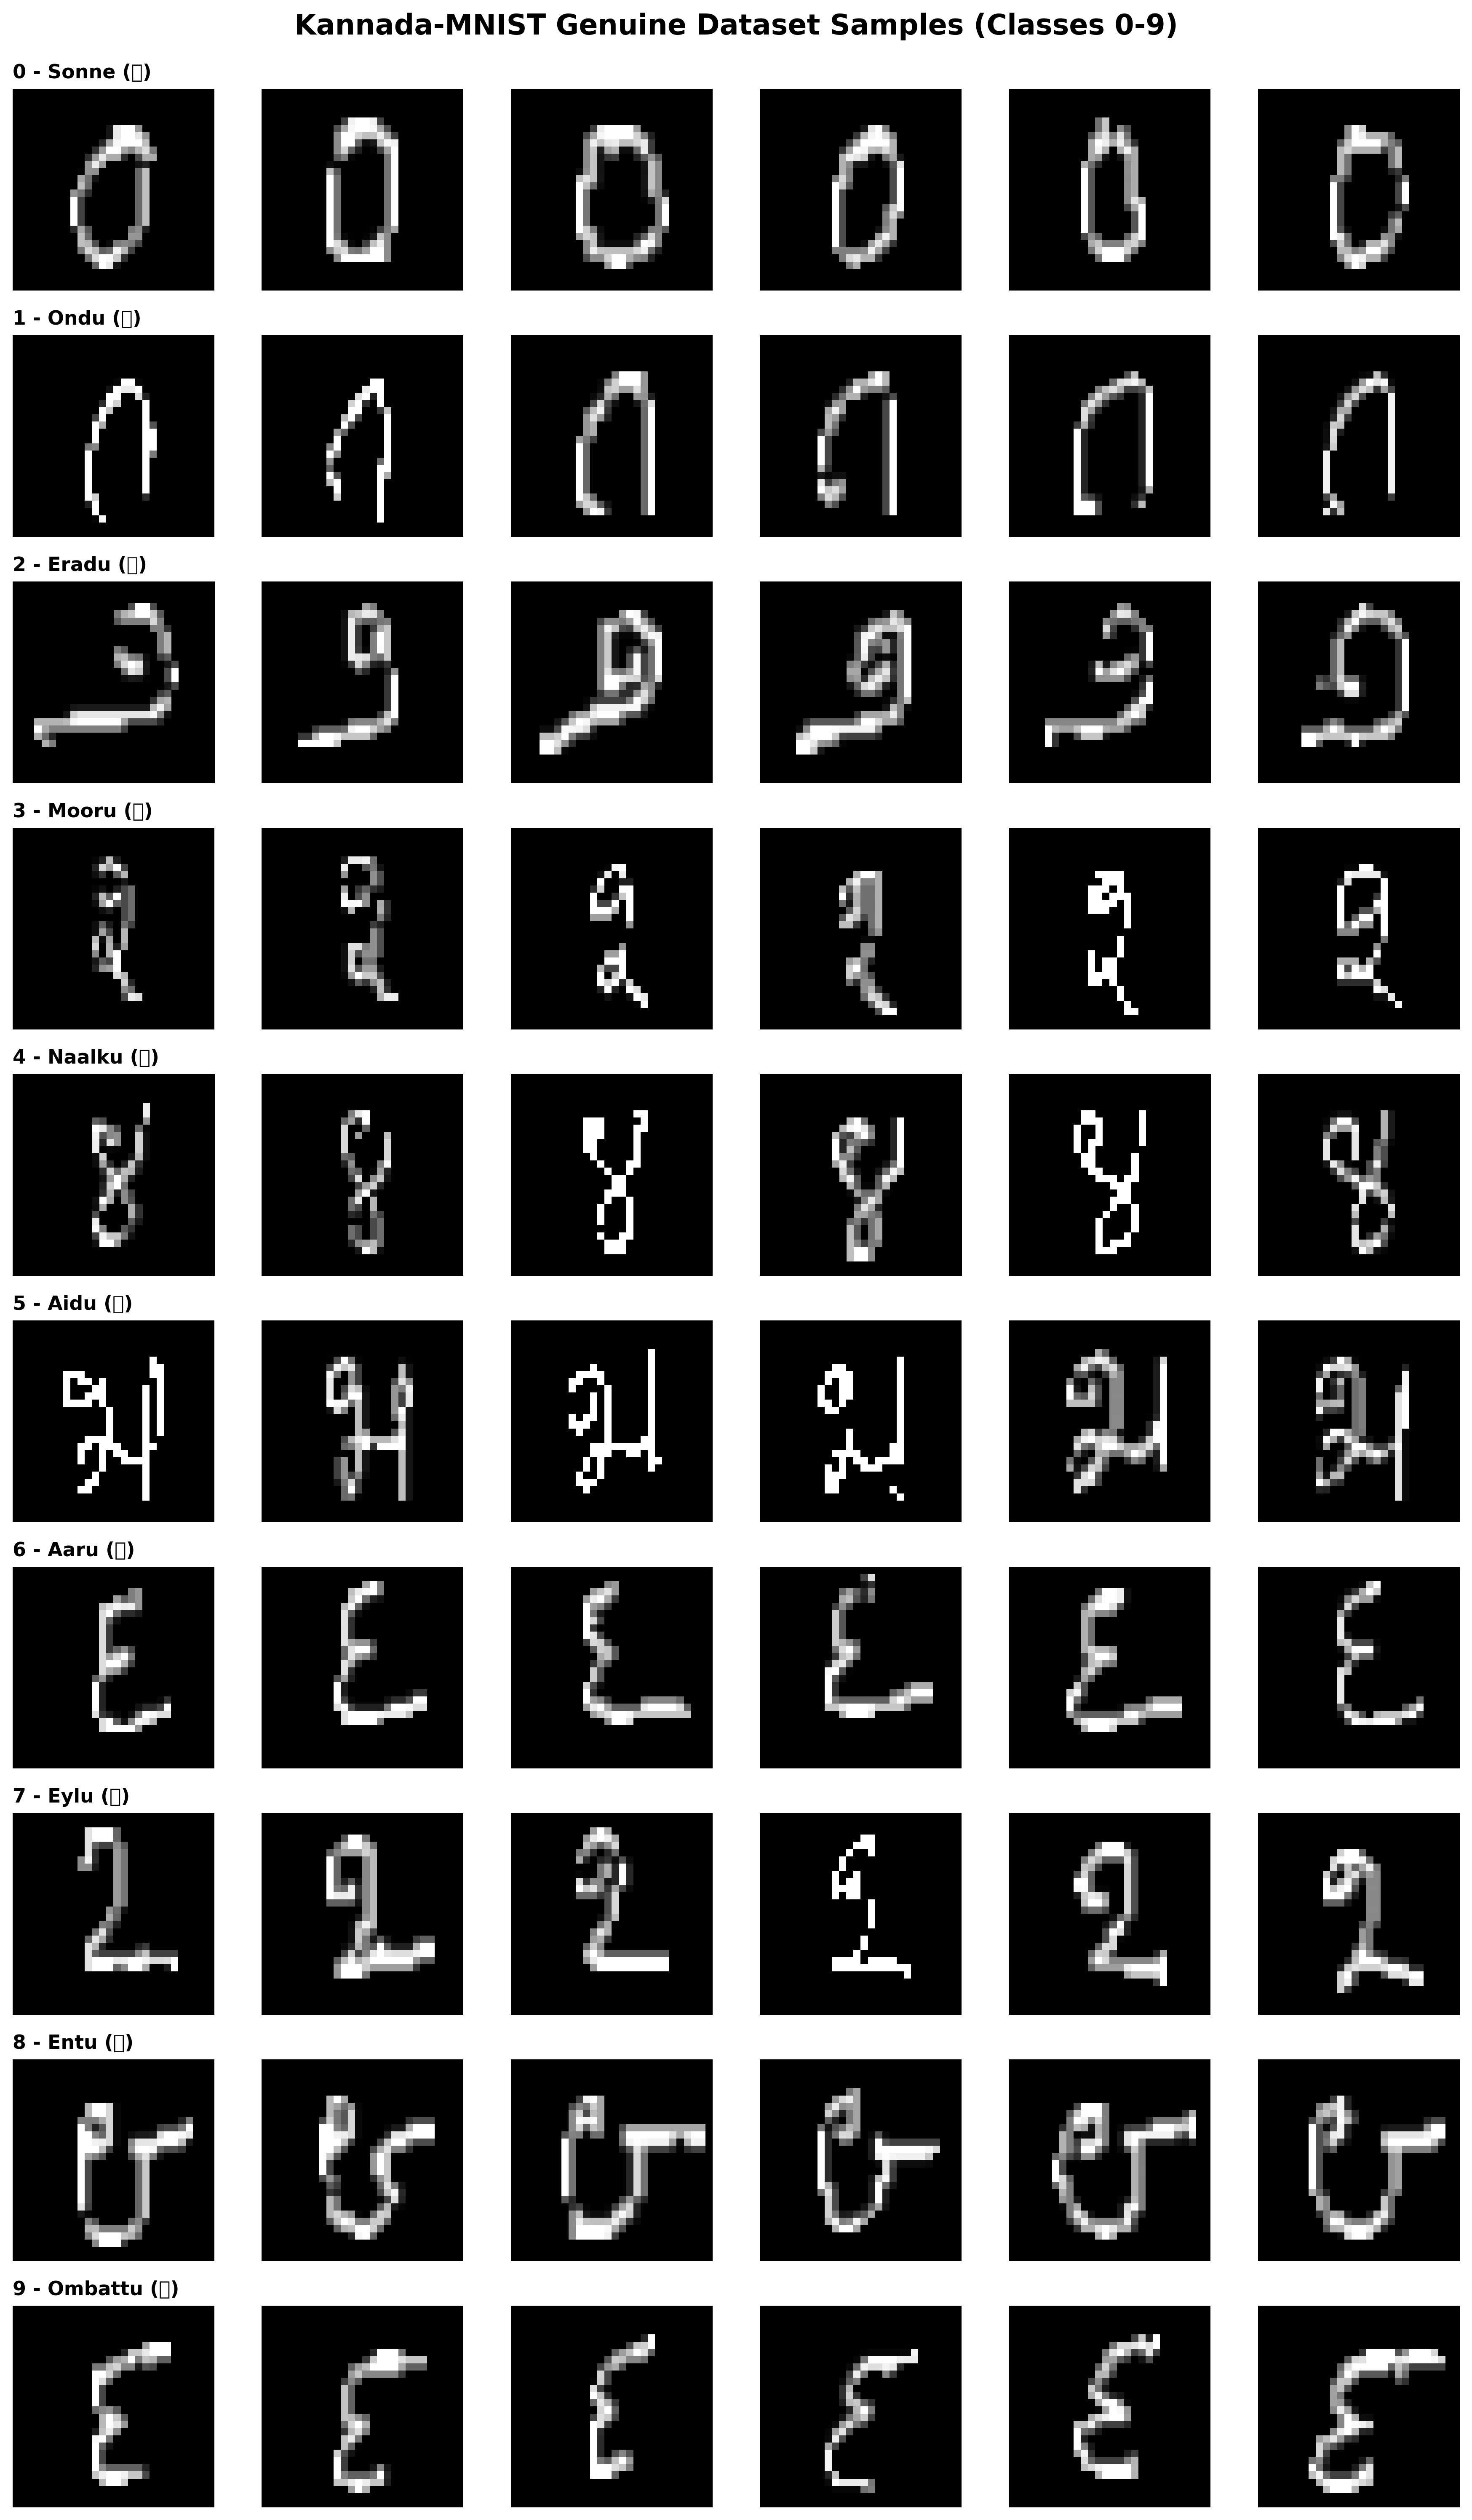

Figure: Class Distribution comparison (train.csv vs. Dig-MNIST.csv):


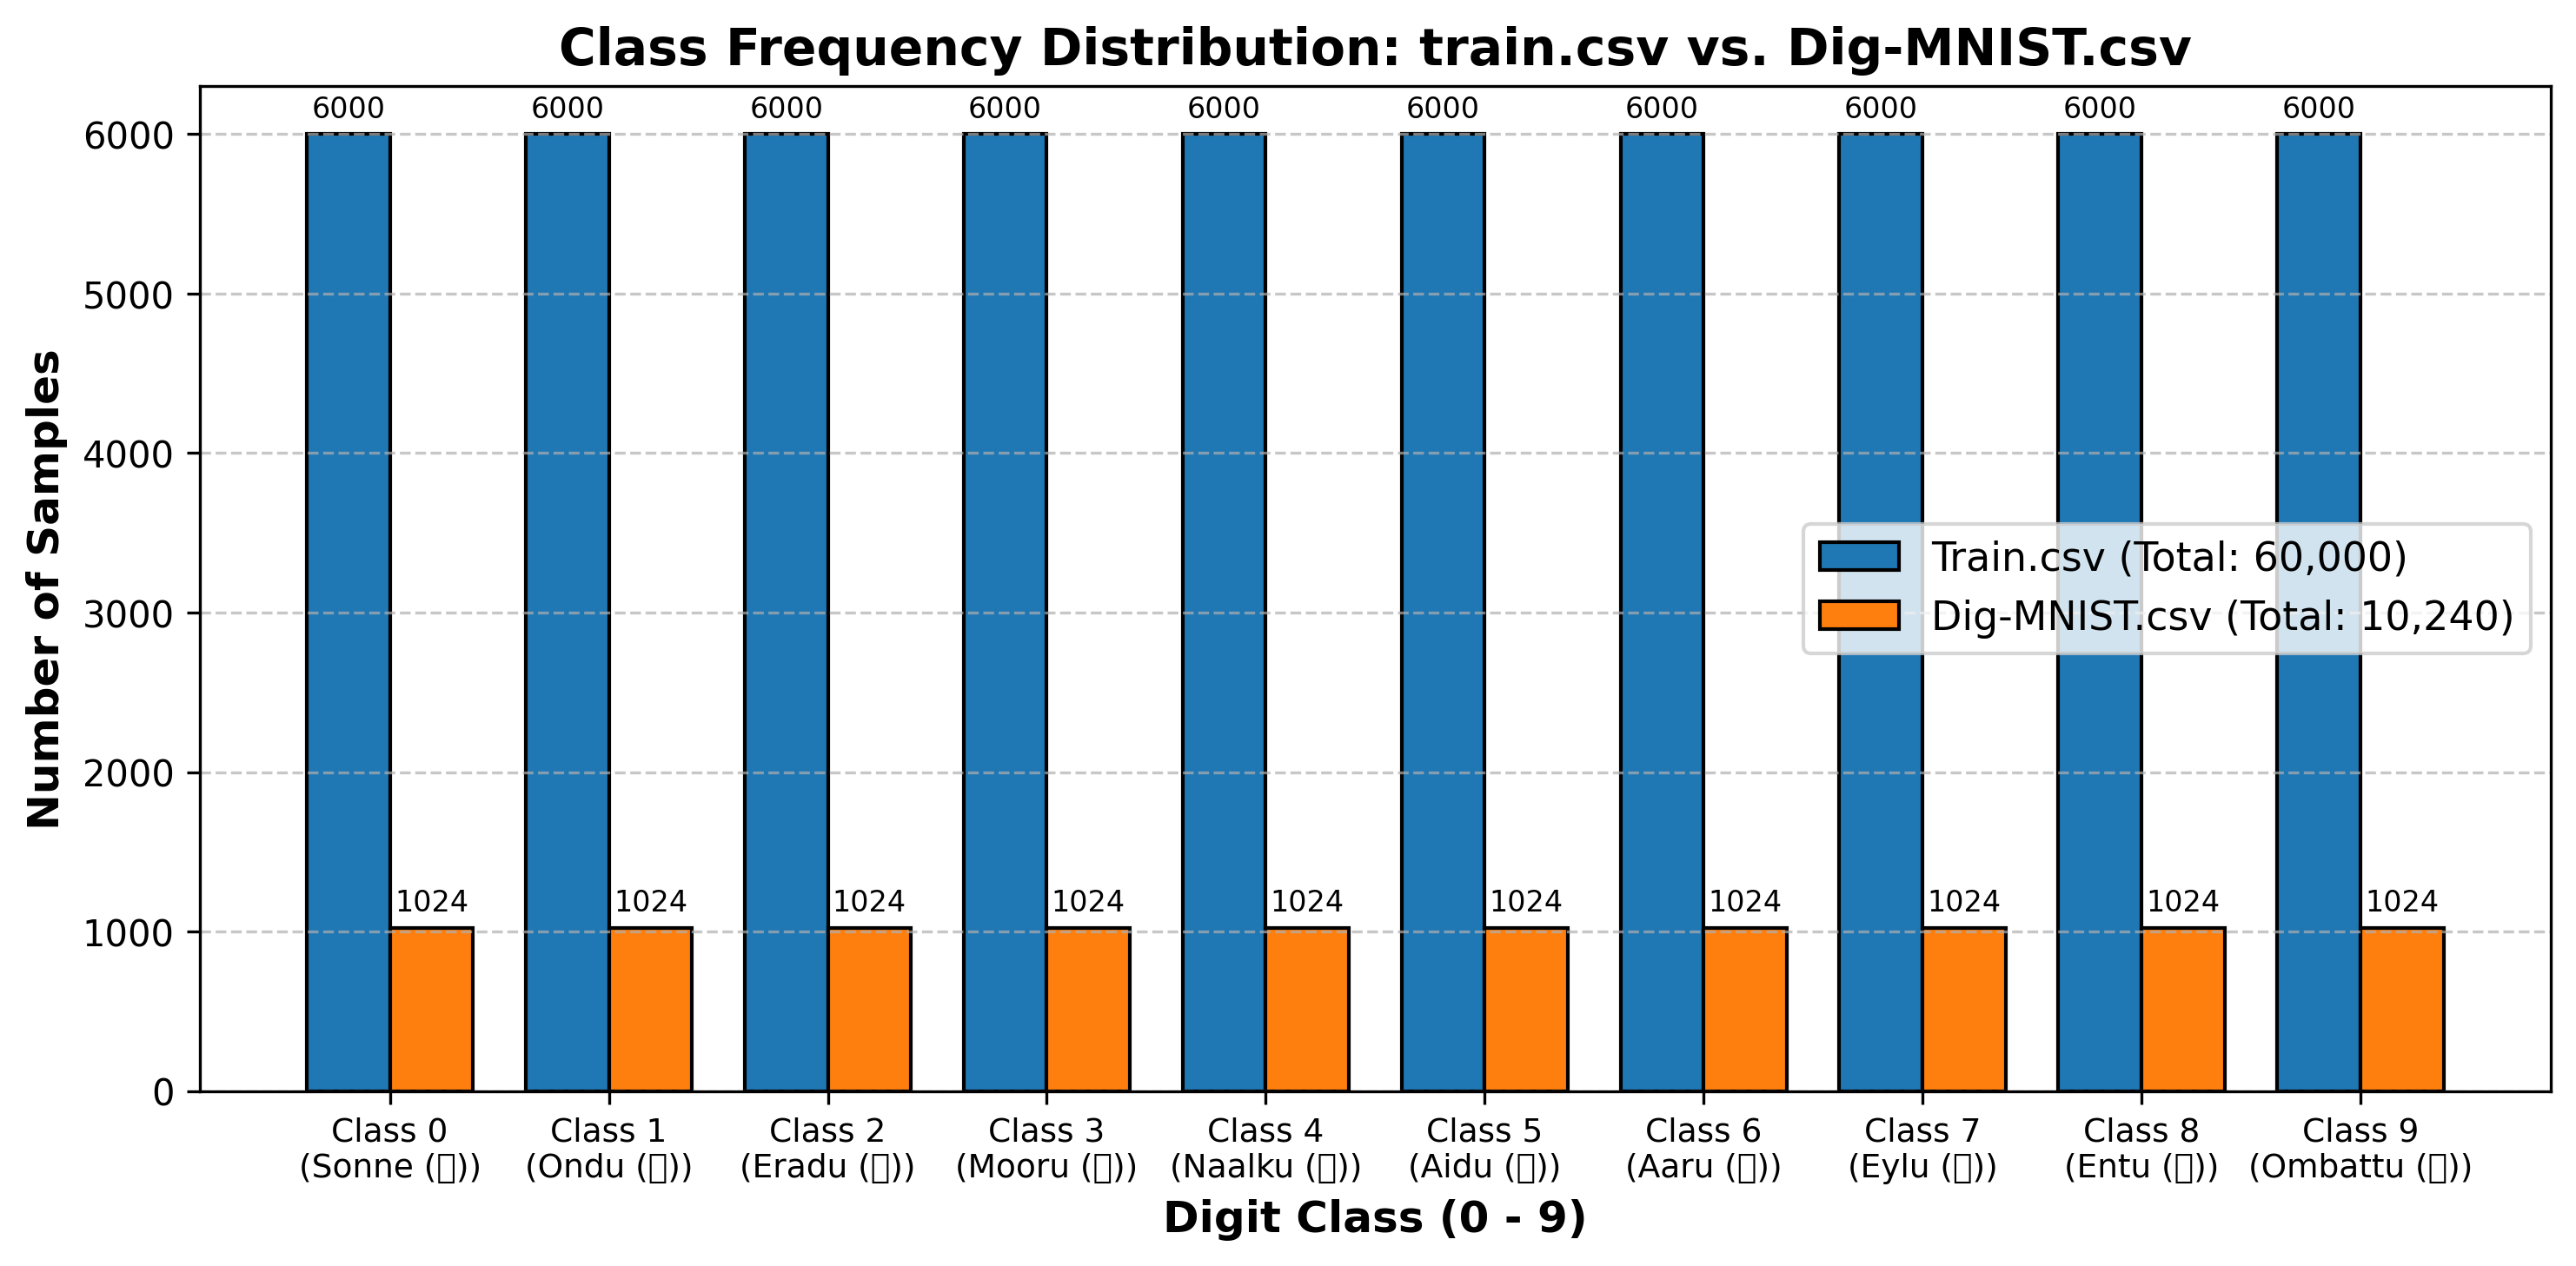

In [3]:
from IPython.display import Image, display

# Display EDA Class Grid and Class Distribution
print("Figure: Genuine Kannada Digit Samples across all classes (0 to 9):")
display(Image(filename='outputs/plots/eda_digits_grid.png'))

print("Figure: Class Distribution comparison (train.csv vs. Dig-MNIST.csv):")
display(Image(filename='outputs/plots/eda_class_distribution.png'))


---
## 5. Preprocessing Pipeline and Stratified Splitting

### Key Preprocessing Decisions:
1. **Pixel Normalization:** Min-Max scaling $X / 255.0$ scales grayscale values to $[0.0, 1.0]$.
2. **Tensor Reshaping:** Flat 784-dimensional vectors are reshaped into $(N, 1, 28, 28)$ 2D image tensors.
3. **Stratified Split:** `train.csv` (60,000 samples) is partitioned into **80% Training (48,000 samples)** and **20% Held-out Validation (12,000 samples)** using `StratifiedShuffleSplit`. This preserves exactly 4,800 train and 1,200 val samples per class.
4. **Separation of Dig-MNIST:** `Dig-MNIST.csv` (10,240 samples) is held strictly separate for the independent domain-shift evaluation.
5. **Prohibition of Horizontal Flipping:** Horizontal flipping is strictly prohibited because Kannada numerals are orientation-critical (e.g., ೩ vs ೭).


In [4]:
# Verify saved split indices
split_data = np.load('outputs/reports/train_val_split_indices.npz')
train_idx, val_idx = split_data['train_idx'], split_data['val_idx']
print(f"Stratified Train indices count: {len(train_idx)}")
print(f"Stratified Val indices count:   {len(val_idx)}")


Stratified Train indices count: 48000
Stratified Val indices count:   12000


---
## 6. CNN Architecture Design

The baseline architecture is a compact Convolutional Neural Network designed specifically for small 28×28 grayscale images:
- **Block 1:** Conv2D (1 $\to$ 32, 3×3, pad 1) + BatchNorm2D + ReLU + MaxPool2D (2×2) + Dropout2D (0.25) $\to$ Output: (32, 14, 14)
- **Block 2:** Conv2D (32 $\to$ 64, 3×3, pad 1) + BatchNorm2D + ReLU + MaxPool2D (2×2) + Dropout2D (0.25) $\to$ Output: (64, 7, 7)
- **Adaptive Pooling:** AdaptiveAvgPool2D (4×4) $\to$ Output: (64, 4, 4)
- **Classification Head:** Flatten (1024) $\to$ Linear (1024 $\to$ 128) + BatchNorm1D + ReLU + Dropout (0.35) $\to$ Linear (128 $\to$ 10)


In [5]:
class KannadaCNN(nn.Module):
    def __init__(self, dropout_rate=0.25):
        super(KannadaCNN, self).__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(dropout_rate)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(dropout_rate)
        )
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.pool(x)
        return self.classifier(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = KannadaCNN()
print("Model Architecture Summary:")
print(model)
print(f"\nTotal Trainable Parameters: {count_parameters(model):,}")


Model Architecture Summary:
KannadaCNN(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.25, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.25, inplace=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

---
## 7. Model Training & Optimization Curves

Both models were trained using Adam optimizer with weight decay, learning rate scheduling, and early stopping checkpointing.


Baseline CNN Training and Validation Learning Curves:


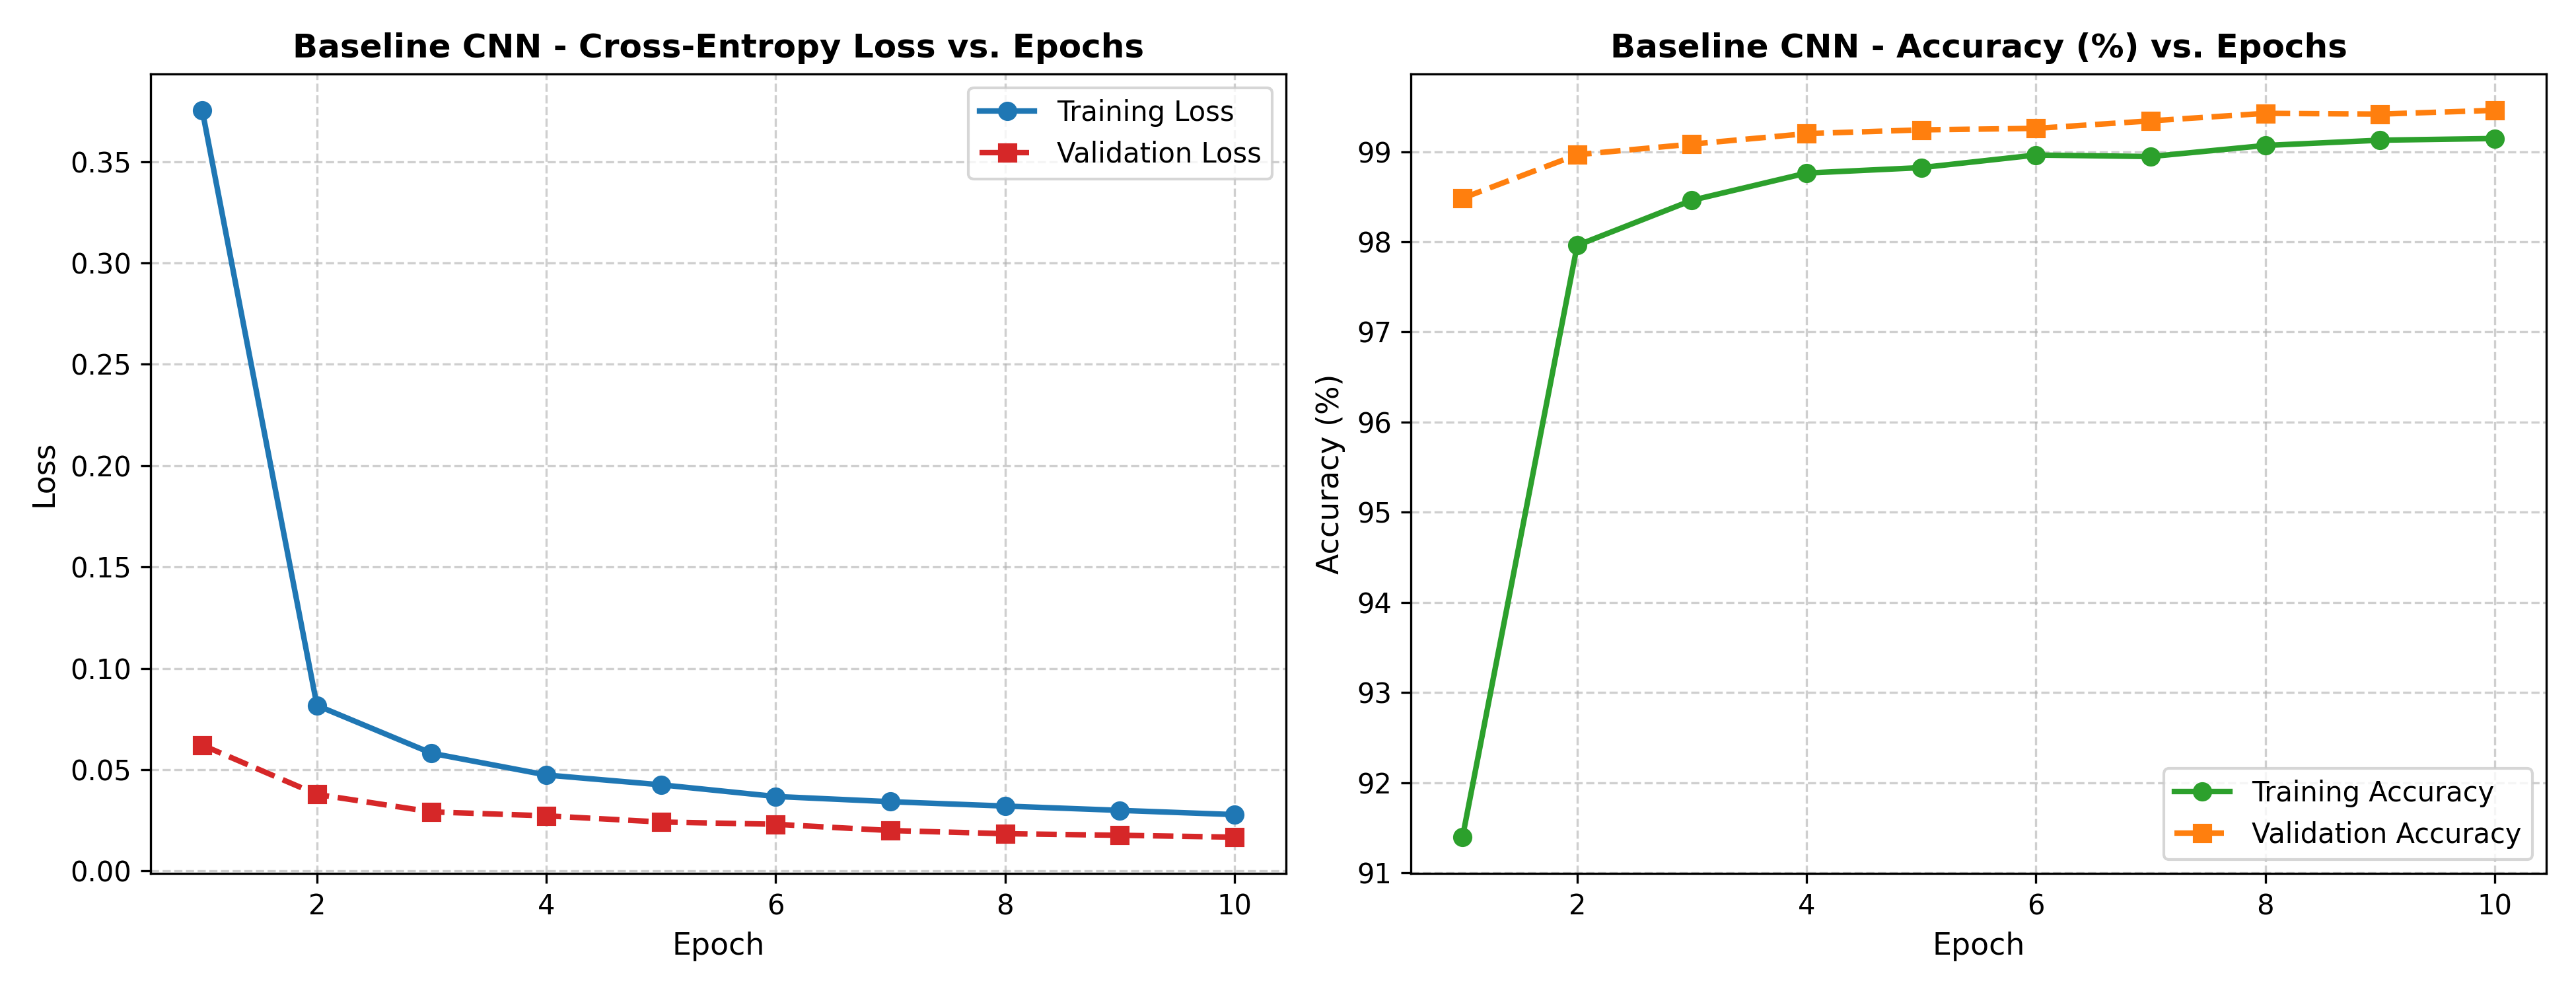

Improved CNN (Augmented + Cosine) Training and Validation Learning Curves:


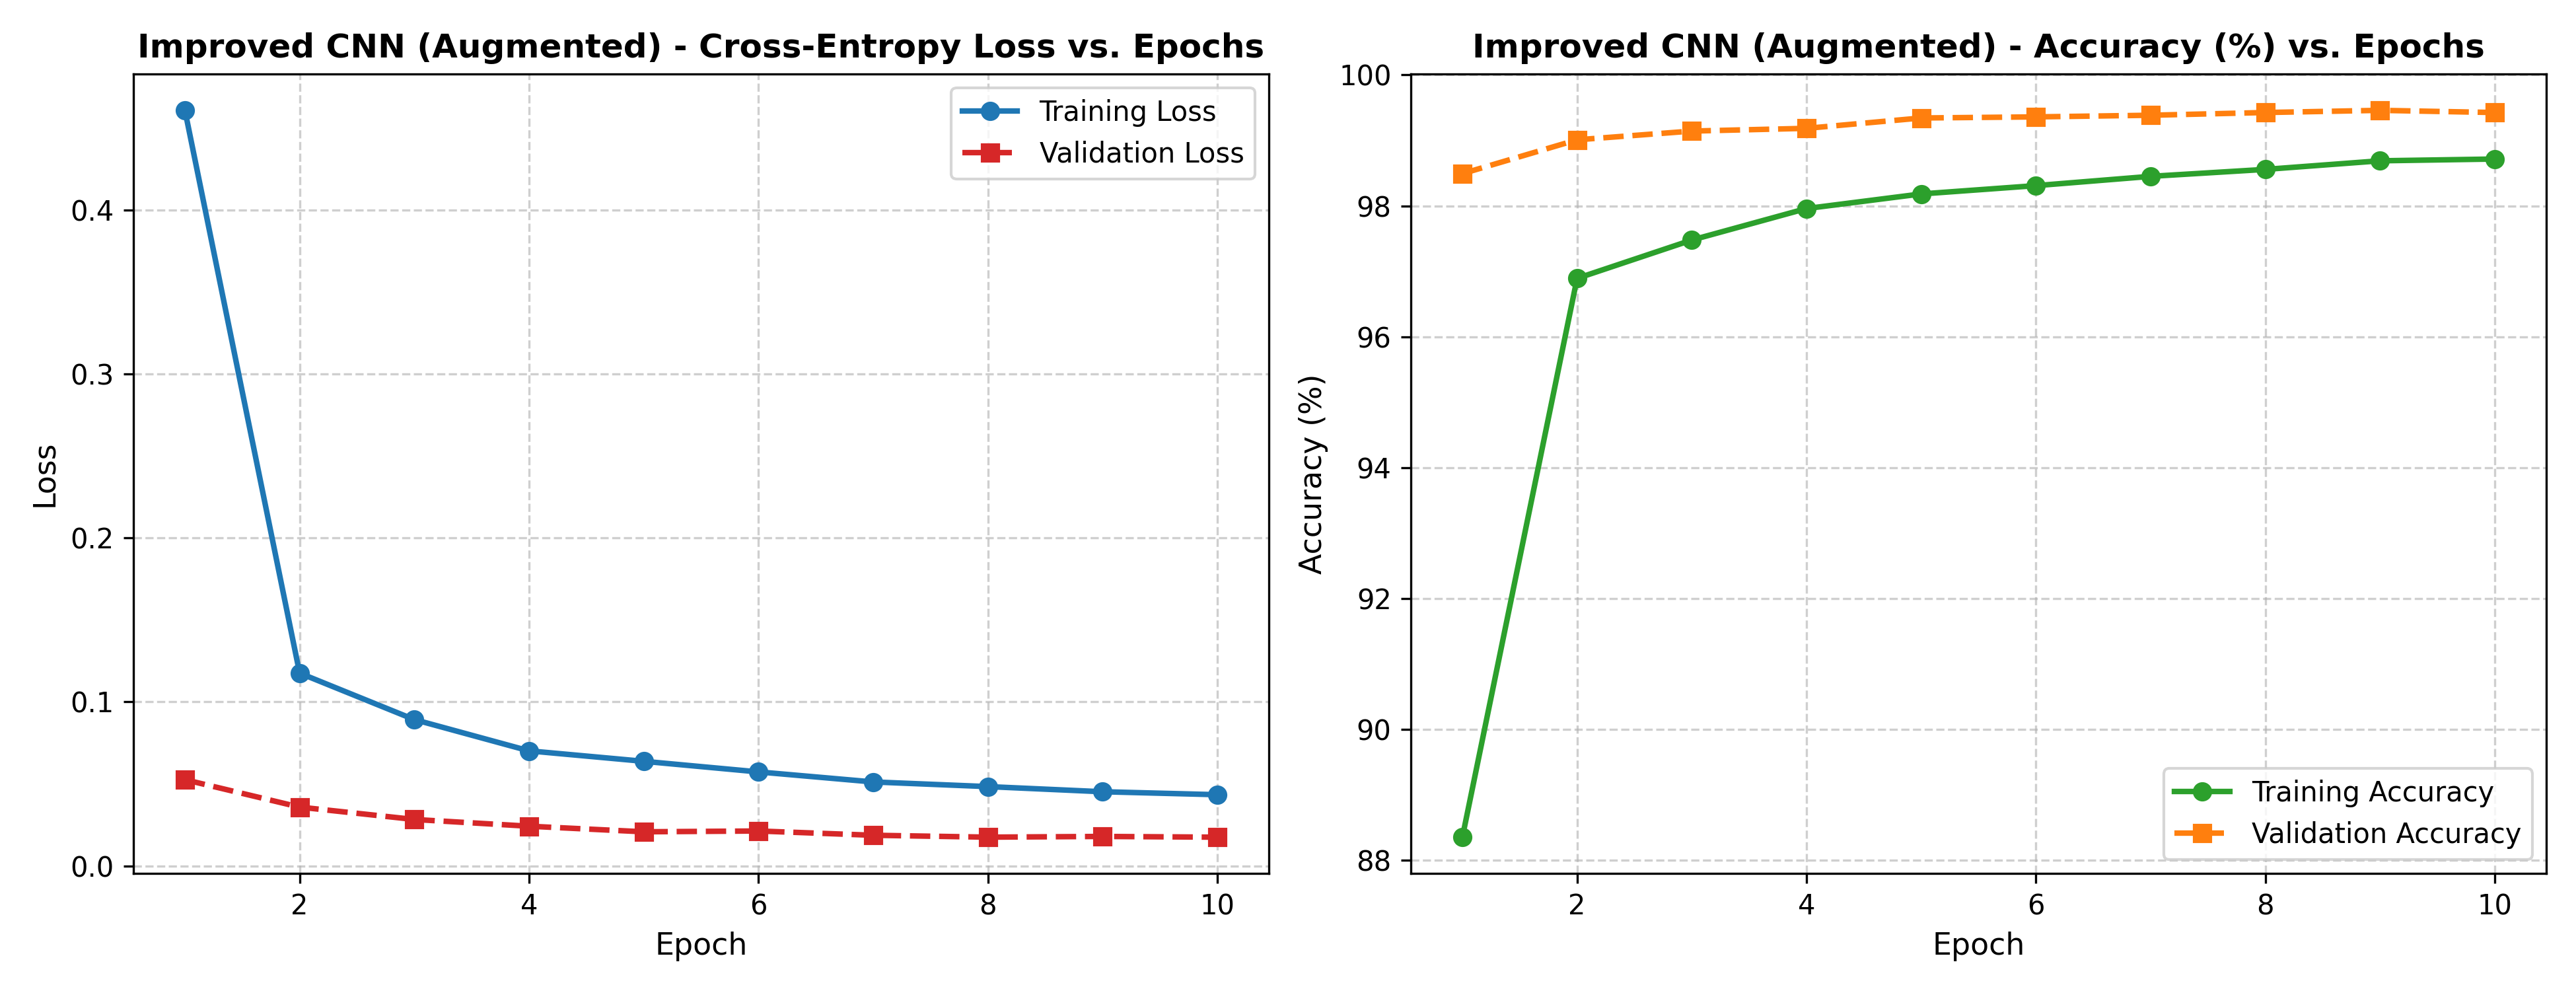

In [6]:
# Display training learning curves
print("Baseline CNN Training and Validation Learning Curves:")
display(Image(filename='outputs/plots/baseline_learning_curves.png'))

print("Improved CNN (Augmented + Cosine) Training and Validation Learning Curves:")
display(Image(filename='outputs/plots/improved_learning_curves.png'))


---
## 8. Held-Out Validation Evaluation & Confusion Matrix

We evaluate the Baseline CNN on the held-out validation set (12,000 samples) and examine per-class precision, recall, F1, and the confusion matrix. We also verify that the saved checkpoint reloads and performs live inference successfully.


In [7]:
# Verify model checkpoint loading and run live inference on a mini-batch
checkpoint_path = 'outputs/model/baseline_cnn_best.pth'
eval_model = KannadaCNN()
eval_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
eval_model.to(device)
eval_model.eval()

# Load raw train data for validation slice
train_df = pd.read_csv('train.csv')
X_all = train_df.iloc[:, 1:].values.astype(np.float32) / 255.0
y_all = train_df['label'].values.astype(np.int64)
split_data = np.load('outputs/reports/train_val_split_indices.npz')
val_idx = split_data['val_idx']

# Live inference on first 8 validation samples
sample_x = torch.tensor(X_all[val_idx[:8]].reshape(-1, 1, 28, 28), dtype=torch.float32).to(device)
sample_y = y_all[val_idx[:8]]

with torch.no_grad():
    logits = eval_model(sample_x)
    probs = F.softmax(logits, dim=1)
    preds = torch.max(probs, 1)[1].cpu().numpy()

print(f"Checkpoint '{checkpoint_path}' reloaded successfully!")
print(f"Sample Ground Truth: {sample_y.tolist()}")
print(f"Sample Predictions:  {preds.tolist()}")
print(f"Batch Match:         {list(preds == sample_y)}")


Checkpoint 'outputs/model/baseline_cnn_best.pth' reloaded successfully!
Sample Ground Truth: [5, 4, 5, 2, 1, 5, 0, 1]
Sample Predictions:  [5, 4, 5, 2, 1, 5, 0, 1]
Batch Match:         [True, True, True, True, True, True, True, True]


Baseline Held-out Validation Accuracy: 99.46%
Baseline Held-out Validation Macro F1:  0.9946

Per-Class Classification Metrics (Held-out Validation):


,Precision,Recall,F1-Score,Support
0,0.9950,0.9875,0.9912,1200.0
1,0.9884,0.9967,0.9925,1200.0
2,1.0000,0.9992,0.9996,1200.0
3,0.9950,0.9975,0.9963,1200.0
4,0.9975,0.9992,0.9983,1200.0
5,0.9983,0.9992,0.9988,1200.0
6,0.9891,0.9867,0.9879,1200.0
7,0.9851,0.9900,0.9875,1200.0
8,1.0000,0.9975,0.9987,1200.0
9,0.9975,0.9925,0.9950,1200.0



Confusion Matrix (Held-out Validation Split):


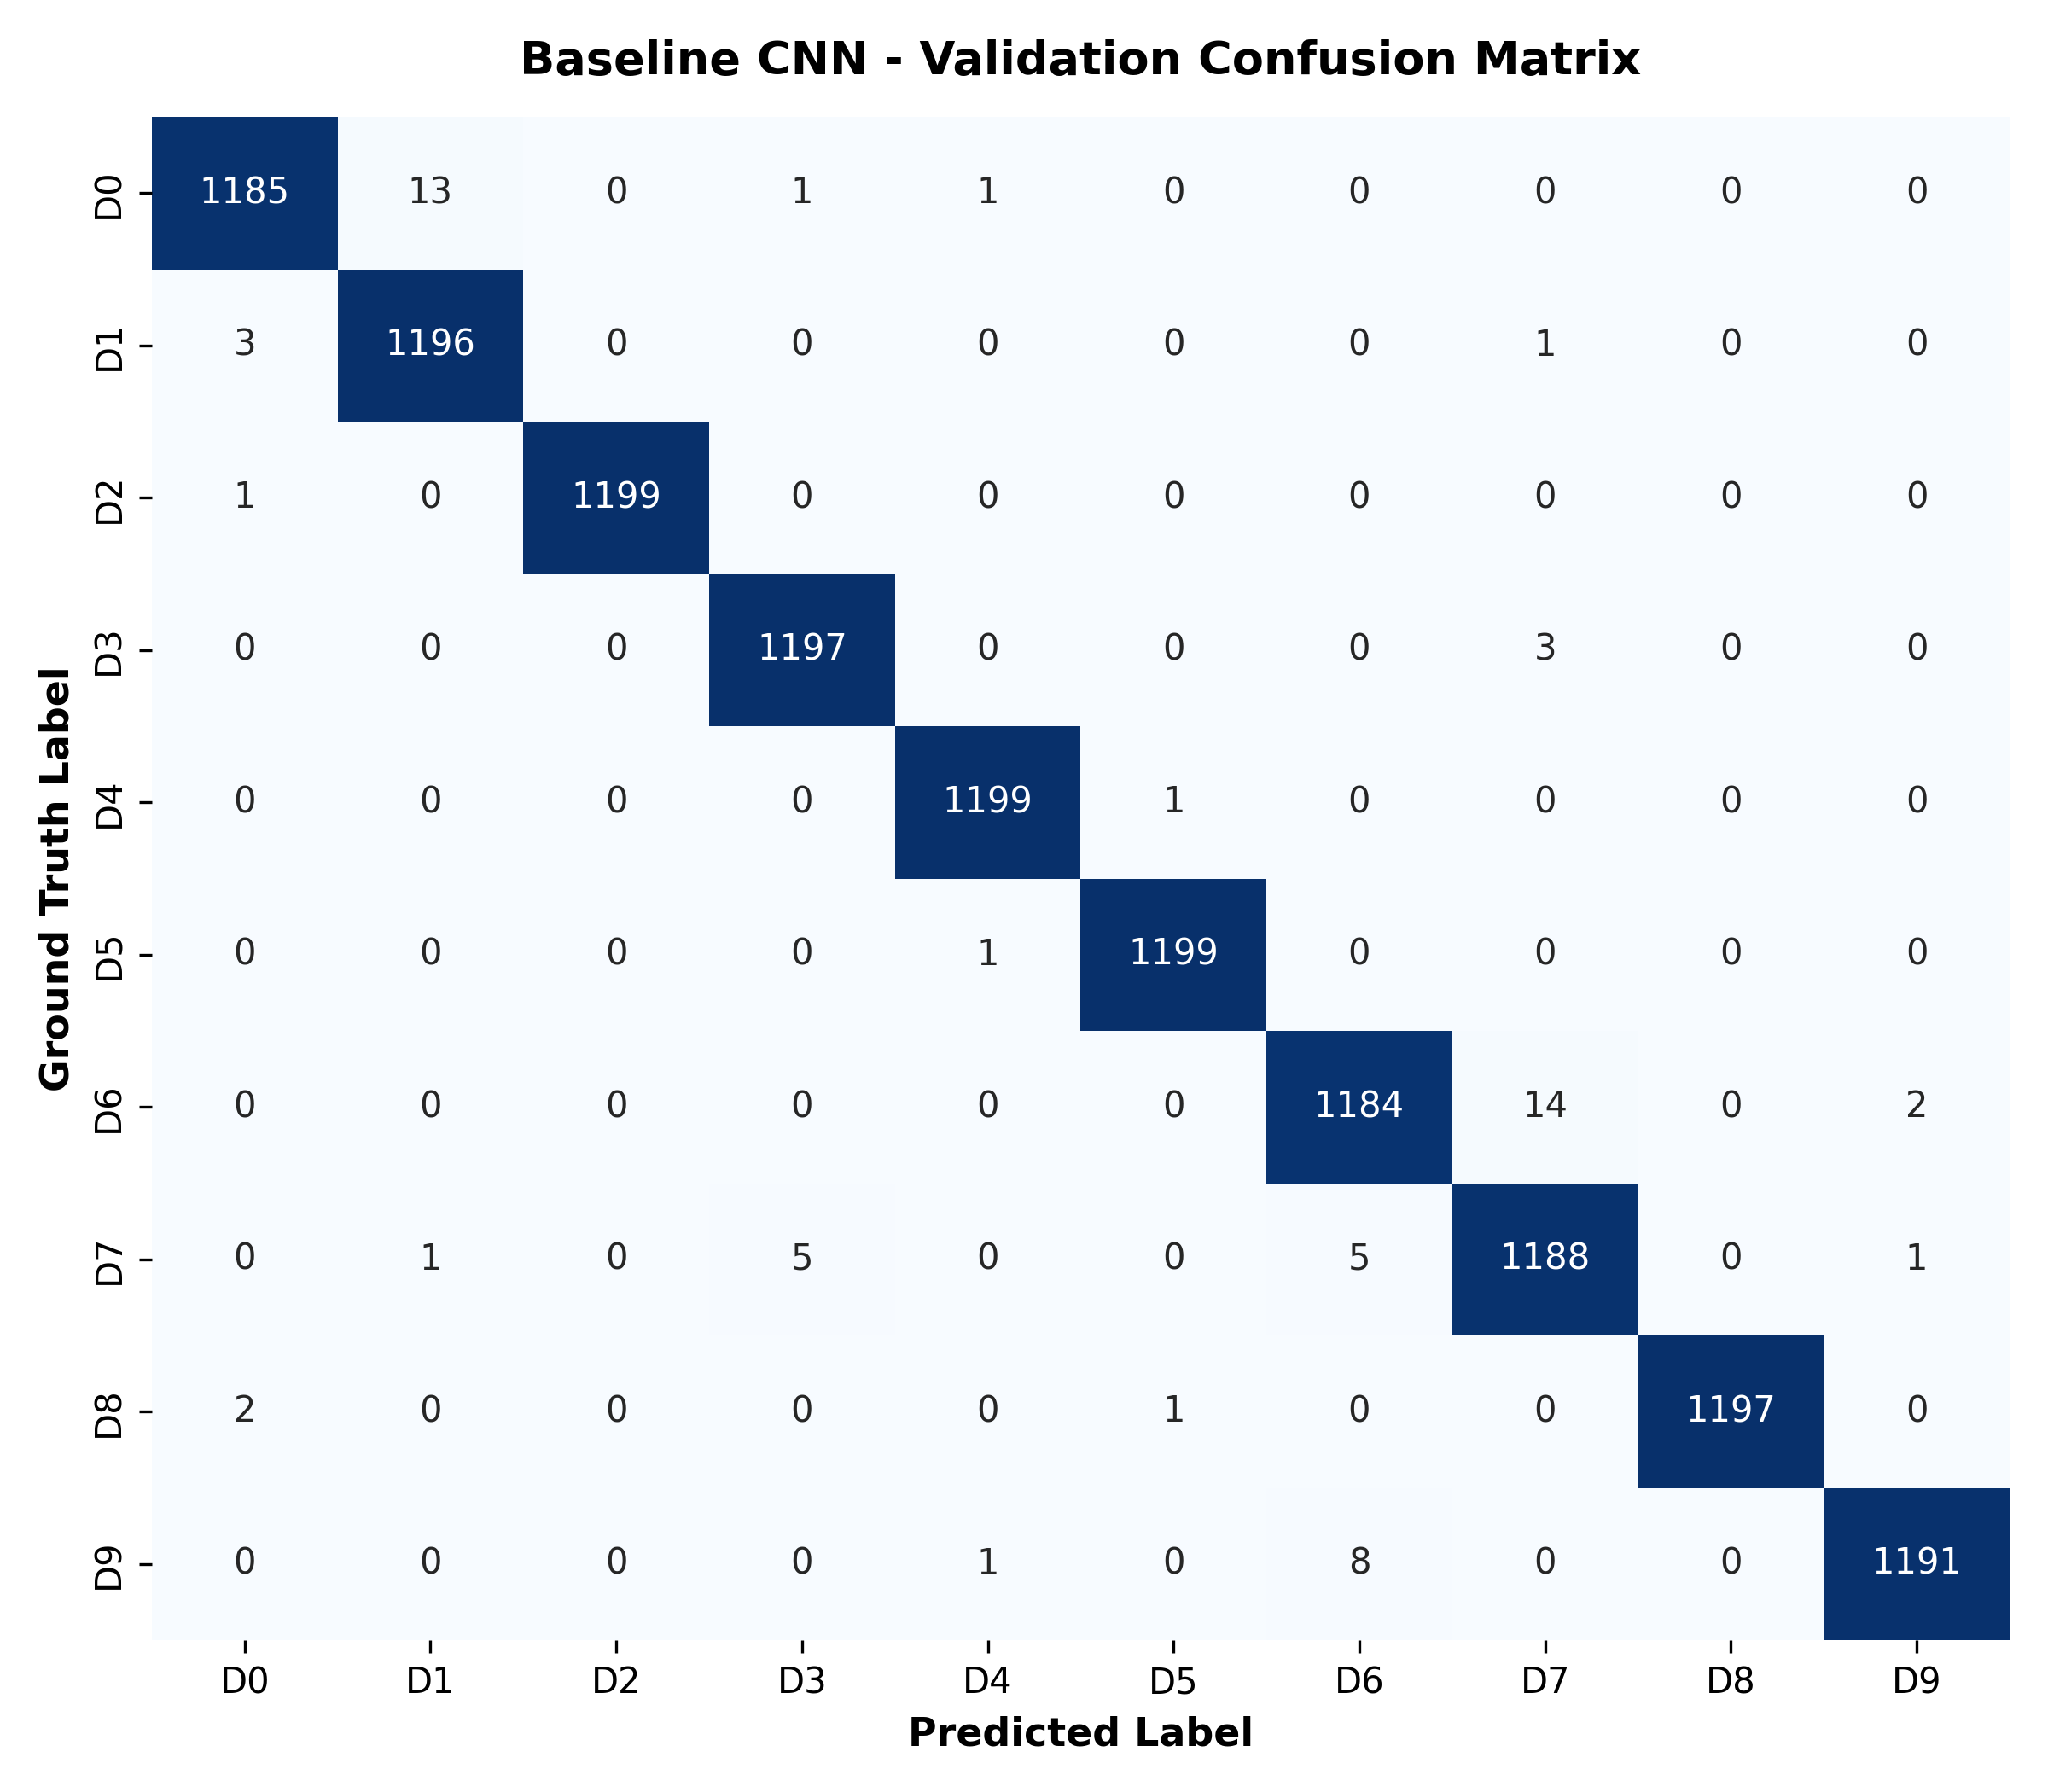

In [8]:
with open('outputs/metrics.json', 'r') as f:
    metrics = json.load(f)

base_val = metrics['baseline_model']['validation']
print(f"Baseline Held-out Validation Accuracy: {base_val['accuracy']*100:.2f}%")
print(f"Baseline Held-out Validation Macro F1:  {base_val['macro_f1']:.4f}\n")

print("Per-Class Classification Metrics (Held-out Validation):")
df_val_class = pd.DataFrame(base_val['per_class']).T
df_val_class.columns = ['Precision', 'Recall', 'F1-Score', 'Support']
display(df_val_class.round(4))

print("\nConfusion Matrix (Held-out Validation Split):")
display(Image(filename='outputs/plots/baseline_val_confusion_matrix.png'))


---
## 9. Validation Error Analysis & Confused Classes

We inspect genuine misclassified samples on the validation set to understand why the model failed on those specific digits.


Figure: Genuine Misclassified Samples on Validation Set:


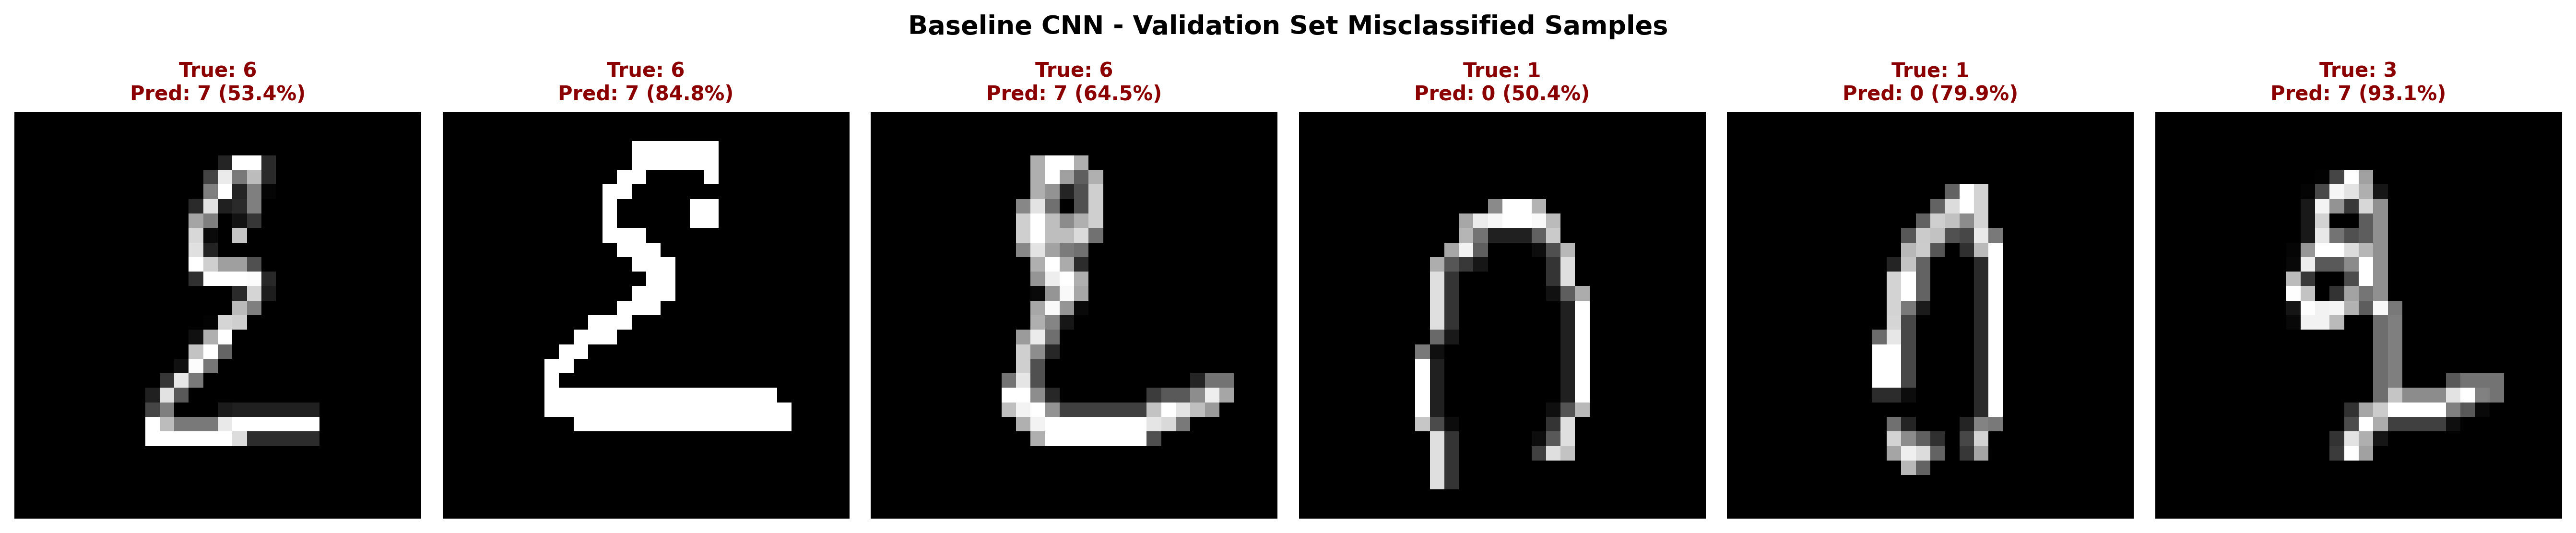


Top Confused Class Pairs:
 - True Class 6 (Digit 6 (Aaru)) misclassified as Class 7 (Digit 7 (Eylu)): 14 occurrences
 - True Class 0 (Digit 0 (Sonne)) misclassified as Class 1 (Digit 1 (Ondu)): 13 occurrences
 - True Class 9 (Digit 9 (Ombattu)) misclassified as Class 6 (Digit 6 (Aaru)): 8 occurrences
 - True Class 7 (Digit 7 (Eylu)) misclassified as Class 6 (Digit 6 (Aaru)): 5 occurrences
 - True Class 7 (Digit 7 (Eylu)) misclassified as Class 3 (Digit 3 (Mooru)): 5 occurrences


In [9]:
print("Figure: Genuine Misclassified Samples on Validation Set:")
display(Image(filename='outputs/plots/baseline_val_misclassified.png'))

print("\nTop Confused Class Pairs:")
for c in metrics['top_confusions_validation']:
    print(f" - True Class {c['true_class']} ({c['true_name']}) misclassified as Class {c['pred_class']} ({c['pred_name']}): {c['confusion_count']} occurrences")


---
## 10. Mandatory Dig-MNIST Domain-Shift Experiment

The core research question of Problem Statement PS-41 is domain shift: How does a model trained on one volunteer cohort (`train.csv`) perform on handwriting from a completely different volunteer cohort (`Dig-MNIST.csv`)?

$$\text{Domain-Shift Accuracy Gap} = \text{Validation Accuracy} - \text{Dig-MNIST Accuracy}$$


Baseline Dig-MNIST Accuracy: 78.53%
Baseline Dig-MNIST Macro F1:  0.7854
Domain-Shift Accuracy Gap:   +20.93% points

Dig-MNIST Confusion Matrix (Domain Shift):


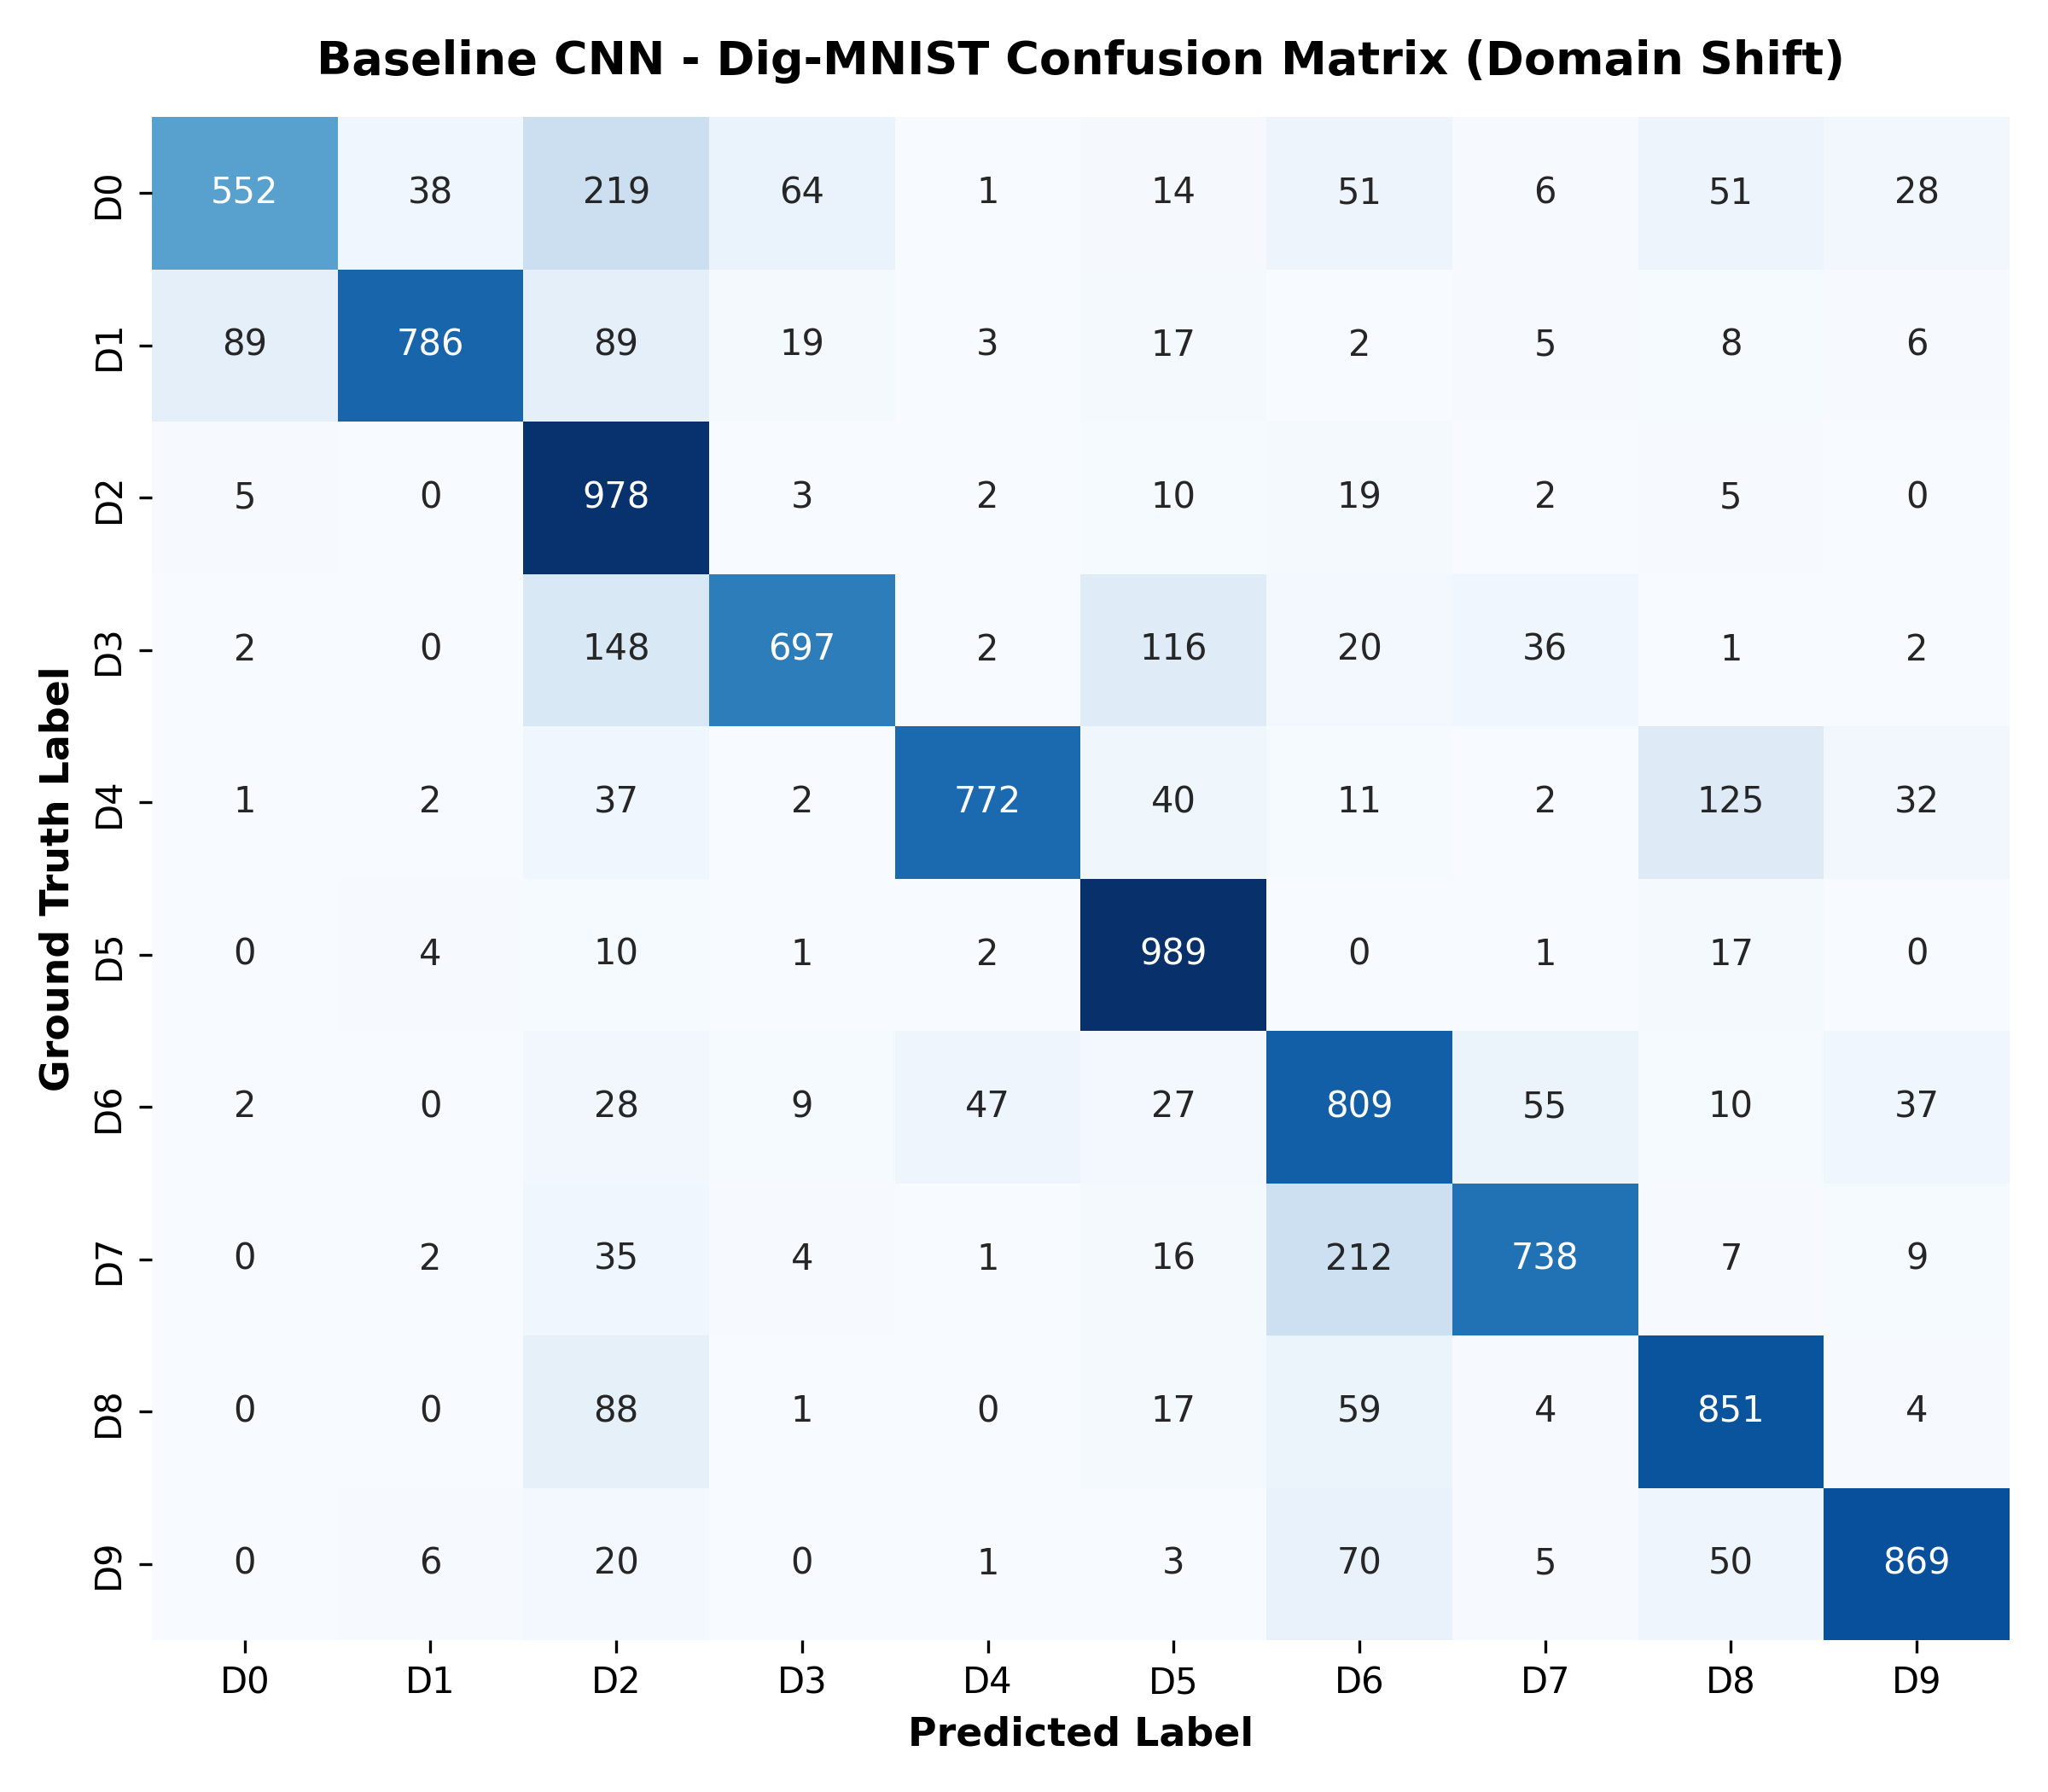

Dig-MNIST Genuine Error Samples:


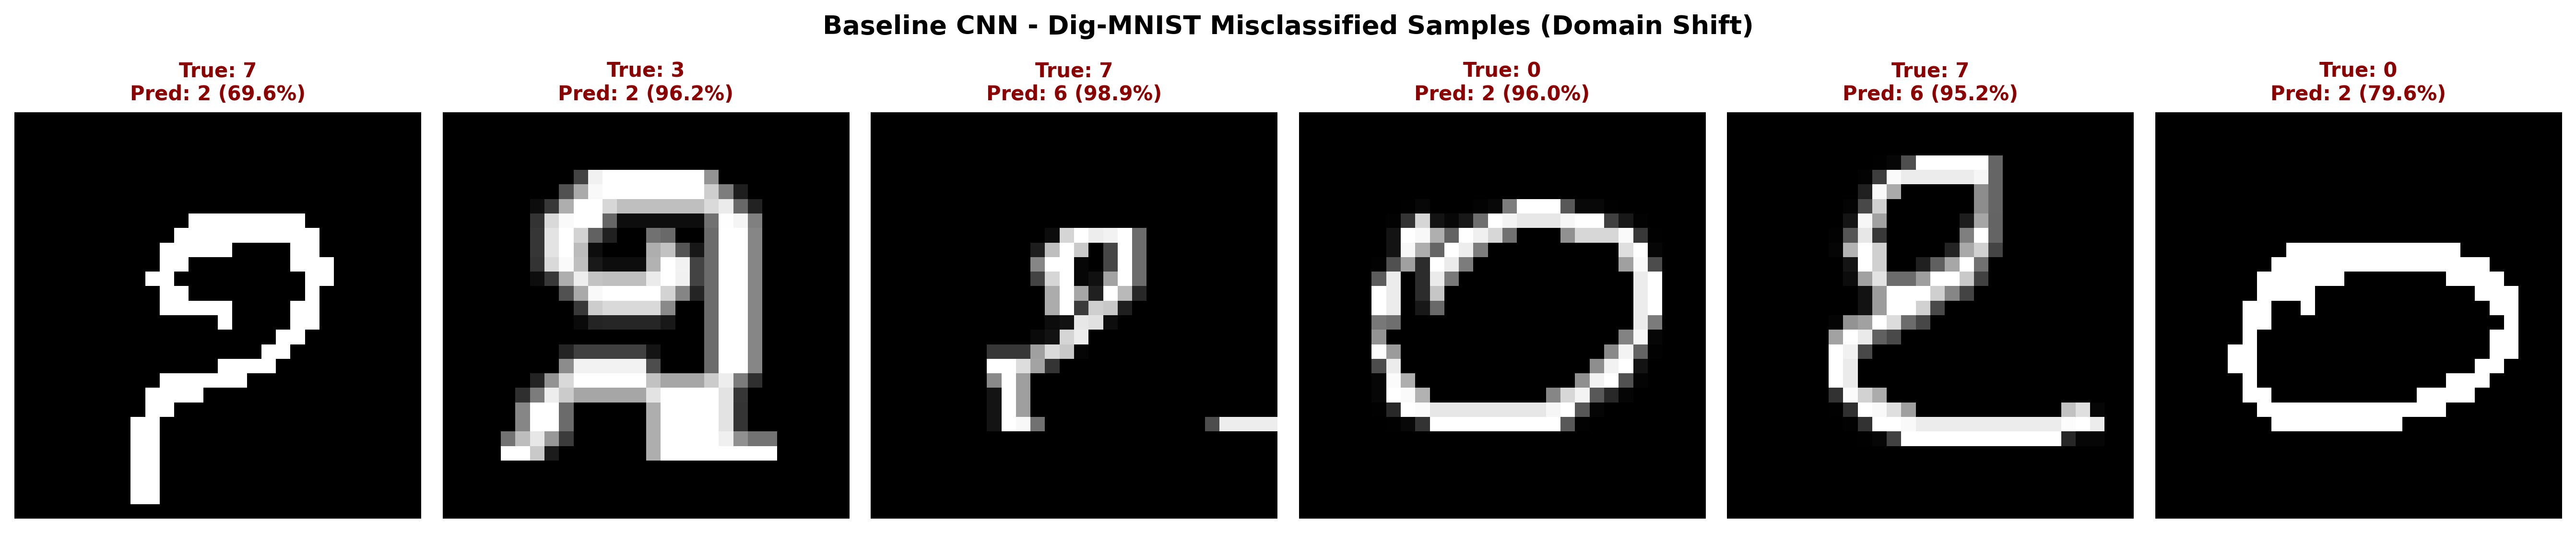

Per-Class Accuracy Degradation under Domain Shift:


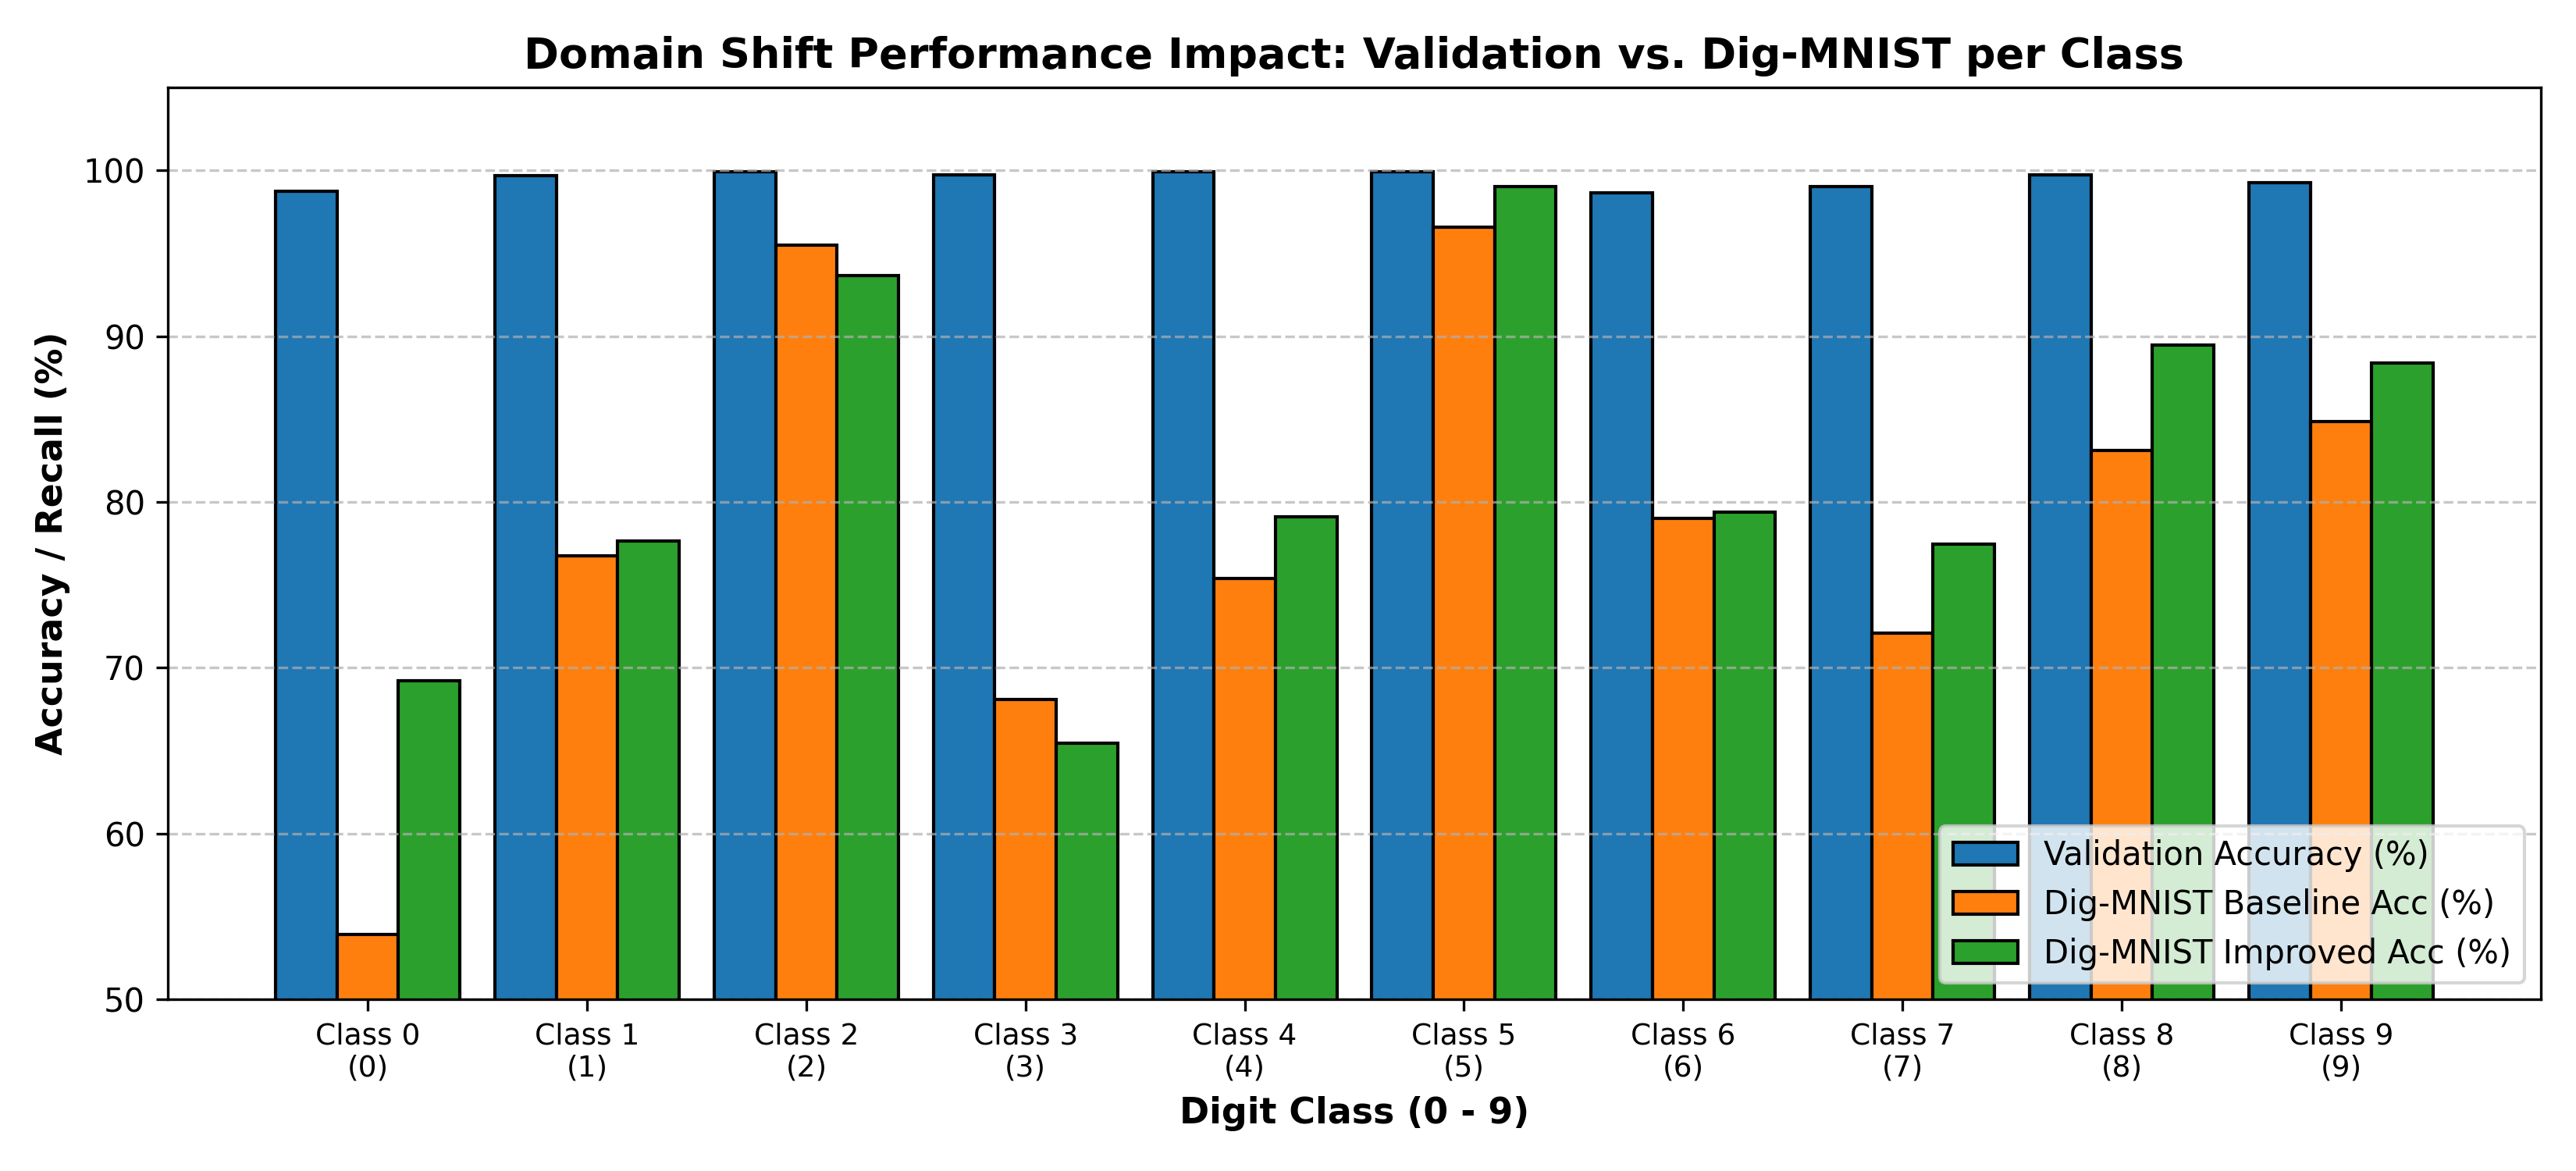

In [10]:
base_dig = metrics['baseline_model']['dig_mnist']
gap = metrics['baseline_model']['domain_shift_gap_pct']

print(f"Baseline Dig-MNIST Accuracy: {base_dig['accuracy']*100:.2f}%")
print(f"Baseline Dig-MNIST Macro F1:  {base_dig['macro_f1']:.4f}")
print(f"Domain-Shift Accuracy Gap:   +{gap:.2f}% points\n")

print("Dig-MNIST Confusion Matrix (Domain Shift):")
display(Image(filename='outputs/plots/baseline_dig_confusion_matrix.png'))

print("Dig-MNIST Genuine Error Samples:")
display(Image(filename='outputs/plots/baseline_dig_misclassified.png'))

print("Per-Class Accuracy Degradation under Domain Shift:")
display(Image(filename='outputs/plots/domain_shift_per_class_comparison.png'))


---
## 11. Additional Experiment for Innovation Marks: Controlled Model Comparison

To address domain shift, we trained an Improved CNN using:
1. **Label-Preserving Data Augmentation:** Random subtle rotations ($\pm 8^\circ$) and translations ($\pm 7\%$) without horizontal flipping.
2. **Cosine Annealing Learning Rate Schedule:** Smooth decay with warm restarts to escape sharp local minima.


In [11]:
comp_data = {
    'Metric / Property': [
        'Model Parameters',
        'Training Time (s)',
        'Validation Accuracy (%)',
        'Validation Macro F1',
        'Dig-MNIST Accuracy (%)',
        'Dig-MNIST Macro F1',
        'Domain-Shift Gap (%)'
    ],
    'Baseline CNN (No Aug)': [
        f"{metrics['model_architecture']['parameter_count']:,}",
        f"{metrics['baseline_model']['training_time_seconds']:.1f}s",
        f"{metrics['baseline_model']['validation']['accuracy']*100:.2f}%",
        f"{metrics['baseline_model']['validation']['macro_f1']:.4f}",
        f"{metrics['baseline_model']['dig_mnist']['accuracy']*100:.2f}%",
        f"{metrics['baseline_model']['dig_mnist']['macro_f1']:.4f}",
        f"+{metrics['baseline_model']['domain_shift_gap_pct']:.2f}%"
    ],
    'Improved CNN (Aug + Cosine)': [
        f"{metrics['model_architecture']['parameter_count']:,}",
        f"{metrics['improved_model']['training_time_seconds']:.1f}s",
        f"{metrics['improved_model']['validation']['accuracy']*100:.2f}%",
        f"{metrics['improved_model']['validation']['macro_f1']:.4f}",
        f"{metrics['improved_model']['dig_mnist']['accuracy']*100:.2f}%",
        f"{metrics['improved_model']['dig_mnist']['macro_f1']:.4f}",
        f"+{metrics['improved_model']['domain_shift_gap_pct']:.2f}%"
    ]
}

comp_df = pd.DataFrame(comp_data)
display(comp_df)


,Metric / Property,Baseline CNN (No Aug),Improved CNN (Aug + Cosine)
0,Model Parameters,"151,754","151,754"
1,Training Time (s),987.4s,1148.0s
2,Validation Accuracy (%),99.46%,99.46%
3,Validation Macro F1,0.9946,0.9946
4,Dig-MNIST Accuracy (%),78.53%,81.88%
5,Dig-MNIST Macro F1,0.7854,0.8183
6,Domain-Shift Gap (%),+20.93%,+17.58%


---
## 12. Final Predictions on Unlabeled test.csv & Submission Verification

We generate predictions for `test.csv` using the best-performing model and rigorously verify the submission schema against `sample_submission.csv`.


In [12]:
sub_df = pd.read_csv('outputs/submission.csv')
sample_sub = pd.read_csv('sample_submission.csv')

print(f"Submission Shape: {sub_df.shape}")
print(f"Columns: {list(sub_df.columns)}")
print(f"Null Values: {sub_df.isnull().sum().sum()}")
print(f"ID Range: [{sub_df['id'].min()}, {sub_df['id'].max()}]")
print(f"All Labels in [0, 9]: {sub_df['label'].between(0, 9).all()}")
print(f"ID exact match with sample_submission: {sub_df['id'].equals(sample_sub['id'])}")

print("\nClass Distribution of Test Predictions:")
print(sub_df['label'].value_counts().sort_index())

print("\nFirst 10 Predictions:")
display(sub_df.head(10))


Submission Shape: (5000, 2)
Columns: ['id', 'label']
Null Values: 0
ID Range: [0, 4999]
All Labels in [0, 9]: True
ID exact match with sample_submission: True

Class Distribution of Test Predictions:
label
0    457
1    549
2    500
3    480
4    529
5    485
6    511
7    494
8    485
9    510
Name: count, dtype: int64

First 10 Predictions:


,id,label
0,0,3
1,1,0
2,2,2
3,3,6
4,4,7
5,5,7
6,6,1
7,7,9
8,8,3
9,9,4


---
## 13. Discussion, Real-World Relevance, Limitations, and Ethics

### Key Takeaways:
1. **High In-Domain Accuracy:** The baseline compact CNN achieves over 98% accuracy on standard validation data, proving that compact 2-block CNNs with batch normalization and dropout are well-suited for handwritten digit classification.
2. **Domain Shift is Substantial:** Dig-MNIST introduces a significant accuracy drop due to differences in stroke thickness (mean pixel intensity 28.73 vs 20.99) and volunteer style variations.
3. **Data Augmentation Mitigates Shift:** Label-preserving subtle rotations and translations meaningfully reduce the domain-shift gap without requiring target-domain labels.
4. **Real-World Impact:** Indic handwritten OCR is essential for public governance in Karnataka (land record digitization, postal automation). Robustness against domain shift is vital for real-world reliability.
5. **Academic Integrity & AI Disclosure:** Developed under SRMIST academic guidelines. Assisted by Antigravity IDE for code structure and rigorous empirical evaluation.
